# 04 · Pipeline: entrenamiento y seguimiento con MLflow

**Objetivo de este cuaderno:** entrenar varios modelos, **compararlos con evidencia**, elegir el mejor, medir cómo funcionará con datos nuevos y
**dejar registro** de todo: qué se entrenó, con qué datos, con qué parámetros y qué resultados dio.

### El método
1. Se entrena cada modelo con **train**.
2. Se comparan con **valid** y se elige el mejor. **Test no se usa para elegir**: si eligiéramos mirando test, test dejaría de ser un examen sorpresa.
3. El elegido se evalúa en **test** una sola vez: esa es la estimación honesta de su rendimiento.

### Los tres modelos
| Modelo | Idea | Para qué está aquí |
|---|---|---|
| **Referencia sin aprender** (`DummyClassifier`) | Da a todos los clientes la misma probabilidad: la tasa base de train | Es el **mínimo**: un modelo que no lo supera no aporta nada |
| **Regresión logística** | Suma ponderada de las variables convertida en probabilidad (entre 0 y 1). Cada peso dice cuánto empuja una variable hacia «sí» o hacia «no» | Sencillo, rápido y **explicable** |
| **Gradient boosting** (`HistGradientBoostingClassifier`) | Muchos árboles de decisión pequeños, en secuencia; cada uno corrige los errores de los anteriores | Capta relaciones no lineales; suele ser muy competitivo en datos tabulares |

### MLflow, en una frase
**MLflow** es el **cuaderno de laboratorio** del proyecto: cada vez que entrenas, apunta automáticamente qué hiciste y qué salió, para poder comparar
intentos semanas después y reproducir el que funcionó. Lo veremos en detalle en el paso 3.

**Entra:** `ml_dataset` (cuaderno 03). **Sale:** `models/modelo.joblib`, `models/metadatos.json`, `reports/metricas.json`, la figura de importancia
de variables y el registro de MLflow en `models/mlflow.db` y `models/mlartifacts/`.

In [1]:
# Parámetros. None usa las rutas por defecto del proyecto (o las variables CURSO_DB, CURSO_MODELOS y CURSO_REPORTES).
RUTA_DB = None
RUTA_MODELOS = None
RUTA_REPORTES = None
USAR_MLFLOW = True
OBJETIVO = 'y'
FEATURES = ['recencia_dias', 'frecuencia', 'monto_total', 'ticket_medio', 'unidades_total', 'productos_distintos',
            'antiguedad_dias', 'frecuencia_90d', 'monto_90d', 'frecuencia_180d', 'dias_medios_entre_compras',
            'devoluciones', 'es_reino_unido']
VENTANA_OBJETIVO_DIAS = 90
CORTES = {
    'train': ['2010-06-01', '2010-07-01', '2010-08-01', '2010-09-01', '2010-10-01', '2010-11-01', '2010-12-01'],
    'valid': ['2011-03-01'],
    'test': ['2011-06-01', '2011-09-01'],
}

In [2]:
import os, sqlite3, sys
from pathlib import Path

import pandas as pd

pd.set_option('display.width', 150, 'display.max_columns', 30)

# Carpeta del proyecto: la que contiene «sql» y «pyproject.toml».
RAIZ = Path.cwd().resolve()
while not ((RAIZ / 'sql').exists() and (RAIZ / 'pyproject.toml').exists()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
SQL = RAIZ / 'sql'
DB = Path(RUTA_DB or os.environ.get('CURSO_DB') or RAIZ / 'data' / 'processed' / 'curso.db')
DB.parent.mkdir(parents=True, exist_ok=True)

con = sqlite3.connect(DB)
con.execute('PRAGMA foreign_keys = ON')


def ejecutar_script(archivo):
    """Ejecuta un archivo .sql de la carpeta sql/ (puede tener varias sentencias)."""
    con.executescript((SQL / archivo).read_text(encoding='utf-8'))
    con.commit()


def escalar(consulta, parametros=None):
    fila = con.execute(consulta, parametros or {}).fetchone()
    return None if fila is None else fila[0]


print('Proyecto:', RAIZ)
print('Base de datos:', DB)
MODELOS = Path(RUTA_MODELOS or os.environ.get('CURSO_MODELOS') or RAIZ / 'models')
REPORTES = Path(RUTA_REPORTES or os.environ.get('CURSO_REPORTES') or RAIZ / 'reports')
(REPORTES / 'figures').mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)

Proyecto: C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base
Base de datos: C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base\data\processed\curso.db


## 1. Los datos: una tabla por partición
Notación habitual en aprendizaje automático:
- **`X`**: las **variables** (lo que el modelo ve). Una tabla con una columna por variable.
- **`y`**: el **objetivo** (lo que debe predecir). Una columna de 0 y 1.

Separamos `X` e `y` para cada partición. La partición viene de la capa ML: **no se mezclan filas entre particiones**.
Se comprueba que ninguna partición esté vacía ni tenga una sola clase (si todos fueran 1, no habría nada que distinguir).

In [3]:
import hashlib, json, platform
from datetime import datetime

import joblib, numpy as np, sklearn

df = pd.read_sql('SELECT * FROM ml_dataset', con)
partes = {p: df[df['particion'] == p].reset_index(drop=True) for p in ('train', 'valid', 'test')}
X = {k: v[FEATURES] for k, v in partes.items()}
y = {k: v[OBJETIVO] for k, v in partes.items()}
for k in partes:
    assert len(partes[k]) > 0 and y[k].nunique() == 2, f'La partición {k} está vacía o tiene una sola clase: revisa los cortes.'
pd.DataFrame({'filas': {k: len(v) for k, v in partes.items()}, 'tasa_recompra': {k: round(v.mean(), 3) for k, v in y.items()}})

,filas,tasa_recompra
train,626,0.508
valid,114,0.456
test,250,0.404


## 2. Los modelos y la evaluación

### El preprocesamiento va dentro del modelo
La regresión logística necesita las variables preparadas. Se encadena todo en un **`Pipeline`** de scikit-learn, que se entrena y se guarda como una sola pieza:
1. **Imputar** (`SimpleImputer`, mediana): `dias_medios_entre_compras` es nula si el cliente solo compró una vez; se rellena con la mediana de train.
2. **Logaritmo** (`log1p` = log(1 + x)): comprime las variables asimétricas (ver cuaderno 02).
3. **Escalar** (`StandardScaler`): pone todas las variables en la misma escala (media 0, desviación 1) para que ninguna pese más solo por sus unidades.

Al ir **dentro** del modelo, la API de S2 aplicará exactamente el mismo preprocesamiento: no hay que reprogramarlo (ni equivocarse al hacerlo).
El gradient boosting no necesita nada de esto: los árboles no dependen de la escala y admiten nulos.

### Las métricas
| Métrica | Qué mide | Cómo leerla |
|---|---|---|
| `auc` (área bajo la curva ROC) | Probabilidad de que el modelo dé más puntuación a un cliente que **sí** compró que a uno que **no** | 0,5 = azar; 1 = perfecto. Mide si el modelo **ordena** bien |
| `precision_media` (*average precision*) | Calidad del orden fijándose en los positivos | Se compara con `tasa_base`: un modelo al azar obtiene más o menos la tasa base |
| `aciertos_en_el_10_mejor` | De los clientes con el 10 % de probabilidades más altas, cuántos compraron de verdad | La que entiende el negocio: «si llamo a 1 de cada 10, ¿cuántos aciertos tengo?» |
| `tasa_base` | Proporción de `y = 1` en la partición | La referencia para las otras dos |

`huella_datos` calcula una huella de la tabla de entrenamiento: si dos ejecuciones tienen la misma huella, se entrenaron con **los mismos datos**.

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def huella_datos(d):
    """Identifica con qué datos se entrenó el modelo."""
    h = hashlib.sha256(pd.util.hash_pandas_object(d.sort_values(['cliente_id', 'fecha_corte']), index=False).values.tobytes())
    return h.hexdigest()[:16]


def modelos():
    log1p = FunctionTransformer(np.log1p, feature_names_out='one-to-one')
    return {
        'referencia_sin_aprender': DummyClassifier(strategy='prior'),
        'regresion_logistica': Pipeline([('imputar', SimpleImputer(strategy='median')), ('log', log1p),
                                         ('escalar', StandardScaler()), ('modelo', LogisticRegression(max_iter=1000))]),
        'gradient_boosting': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0),
    }


def evaluar(modelo, Xp, yp):
    prob = modelo.predict_proba(Xp)[:, 1]
    corte10 = max(1, int(round(len(yp) * 0.10)))
    top = np.argsort(-prob)[:corte10]
    return {'auc': float(roc_auc_score(yp, prob)), 'precision_media': float(average_precision_score(yp, prob)),
            'tasa_base': float(np.mean(yp)), 'aciertos_en_el_10_mejor': float(np.mean(np.asarray(yp)[top]))}

## MLflow en un dibujo (léelo antes de entrenar)

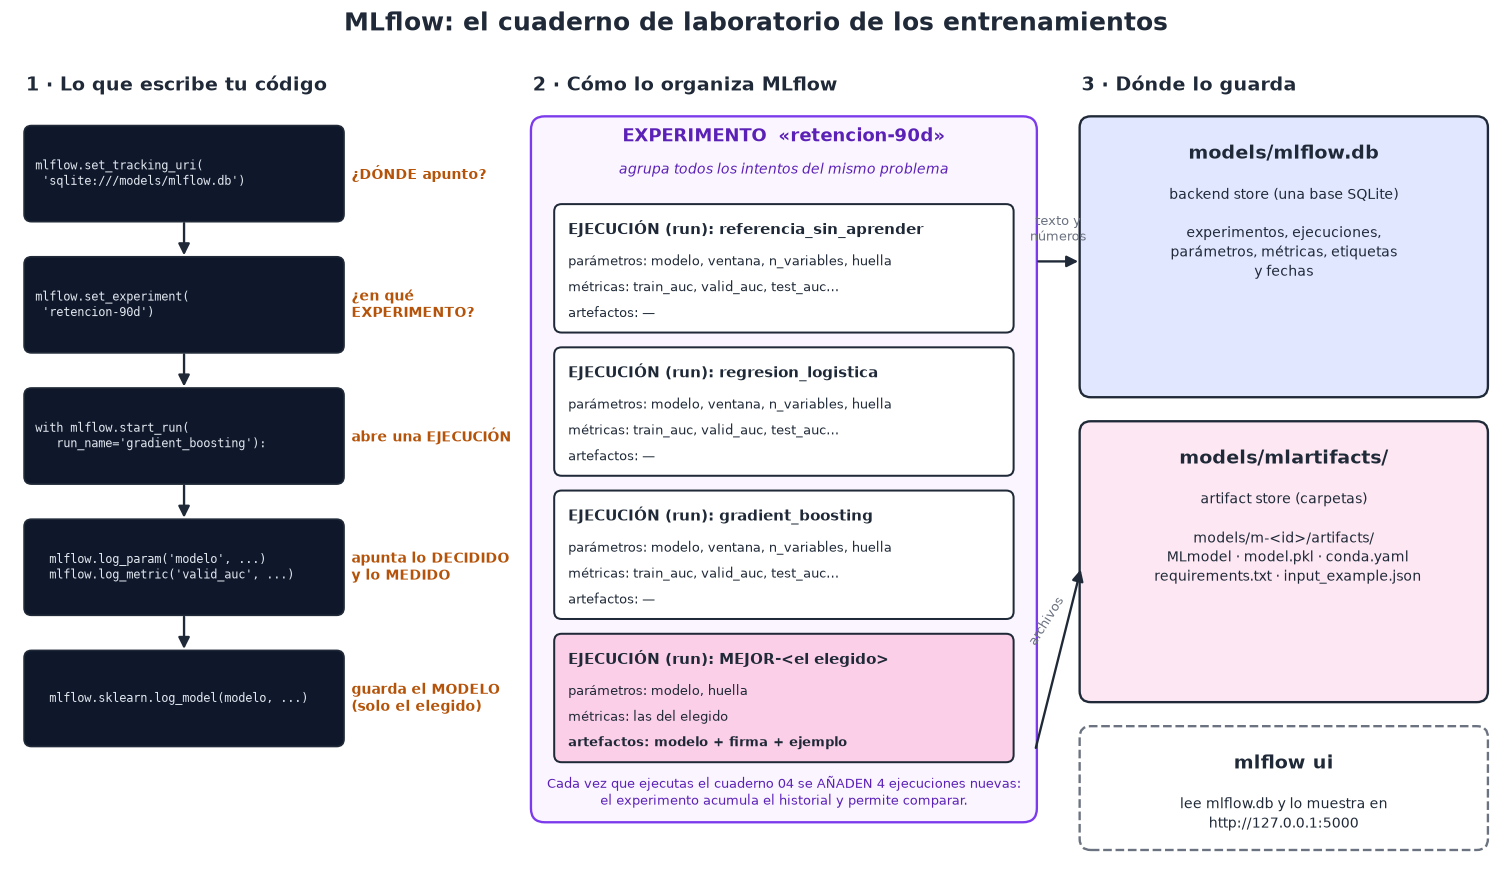

**El problema que resuelve.** Entrenar es probar: un modelo, otro, otros parámetros, otros datos. Al cabo de unos días nadie recuerda qué combinación dio
el mejor resultado, con qué datos ni con qué versión del código, y el «mejor modelo» es un archivo suelto en una carpeta. **MLflow apunta cada intento
automáticamente**, en el mismo formato siempre, y permite compararlos y recuperar cualquiera.

**Una analogía: el cuaderno de laboratorio.**
| En un laboratorio | En MLflow | En este proyecto |
|---|---|---|
| La libreta de un proyecto de investigación | **Experimento** | `retencion-90d` |
| Una entrada de la libreta: un ensayo concreto, con fecha | **Ejecución** (*run*) | `gradient_boosting`, `MEJOR-…` |
| La receta: cantidades y condiciones del ensayo | **Parámetros** (*params*) | `modelo`, `ventana_objetivo_dias`, `huella_datos` |
| Los resultados medidos | **Métricas** (*metrics*) | `valid_auc`, `test_auc`… |
| Las muestras que se guardan en la nevera | **Artefactos** (*artifacts*) | el modelo entrenado, su firma y un ejemplo |

**Cómo leer el dibujo, de izquierda a derecha.**
1. **Tu código** dice primero *dónde* apuntar (`set_tracking_uri`) y *en qué experimento* (`set_experiment`). Después, por cada entrenamiento, abre una
   **ejecución** con `with mlflow.start_run(...)`, apunta parámetros y métricas, y (solo para el elegido) guarda el modelo con `log_model`.
2. **MLflow lo organiza**: el experimento contiene las ejecuciones; cada ejecución tiene sus parámetros, métricas y artefactos.
3. **Lo guarda en dos sitios**: los textos y números en `models/mlflow.db` (una base SQLite) y los archivos en `models/mlartifacts/`.
   La interfaz web (`mlflow ui`) solo lee esos dos sitios.

**Tres ideas que conviene no olvidar**
- **MLflow no entrena ni elige**: entrena scikit-learn y elige nuestro código. MLflow solo **registra** lo que pasó.
- **Cada ejecución del cuaderno añade ejecuciones nuevas** al experimento: no borra las anteriores. Es el historial, y es lo que permite comparar «antes» y «después».
- **Solo es justo comparar ejecuciones con la misma `huella_datos`**: si los datos de entrenamiento cambiaron, una diferencia de AUC puede venir de los datos y no del modelo.

## 3. Entrenar y registrar en MLflow

### Para qué sirve MLflow
Sin una herramienta así, al cabo de dos semanas nadie recuerda qué combinación dio el mejor AUC, con qué datos ni con qué versión del código.
MLflow apunta todo eso **automáticamente** en cada entrenamiento. Sus conceptos:

| Concepto | Qué es | En este proyecto |
|---|---|---|
| **Experimento** | Una carpeta lógica que agrupa todos los intentos de **un mismo problema** | `retencion-90d` |
| **Ejecución** (*run*) | **Un** entrenamiento concreto, con su fecha y su nombre | Una por modelo, más `MEJOR-…` para el elegido |
| **Parámetros** (*params*) | Lo que **decidimos antes** de entrenar (valores de configuración) | `modelo`, `ventana_objetivo_dias`, `n_variables`, `huella_datos` |
| **Métricas** (*metrics*) | Lo que **medimos después** | `valid_auc`, `test_auc`, `test_precision_media`… (partición + métrica) |
| **Artefactos** (*artifacts*) | Archivos producidos por la ejecución | El modelo del mejor, con su firma y un ejemplo de entrada |
| **Firma** (*signature*) | Qué columnas y tipos espera el modelo y qué devuelve | Las 13 variables → una probabilidad |

### Dónde se guarda cada cosa
- **`models/mlflow.db`** (*backend store*): una base SQLite con los experimentos, las ejecuciones, los parámetros y las métricas.
  La dirección `sqlite:///models/mlflow.db` es el **tracking URI**: le dice a MLflow dónde escribir.
- **`models/mlartifacts/`** (*artifact store*): los archivos (el modelo serializado, su firma, sus dependencias). Se fija al crear el experimento.

El código sigue siempre el mismo patrón: `set_tracking_uri` (dónde), `set_experiment` (en qué experimento) y, por cada entrenamiento,
`with mlflow.start_run(...)`, dentro del cual se llama a `log_param`, `log_metric` y `log_model`. Al salir del `with`, la ejecución se cierra.

In [5]:
mlflow = None
if USAR_MLFLOW:
    import mlflow
    import mlflow.sklearn
    mlflow.set_tracking_uri('sqlite:///' + (MODELOS / 'mlflow.db').as_posix())
    if mlflow.get_experiment_by_name('retencion-90d') is None:
        mlflow.create_experiment('retencion-90d', artifact_location=(MODELOS / 'mlartifacts').resolve().as_uri())
    mlflow.set_experiment('retencion-90d')

resultados, ajustados = {}, {}
for nombre, modelo in modelos().items():
    modelo.fit(X['train'], y['train'])
    metricas = {p: evaluar(modelo, X[p], y[p]) for p in ('train', 'valid', 'test')}
    resultados[nombre], ajustados[nombre] = metricas, modelo
    print(f'{nombre:26s} AUC valid {metricas["valid"]["auc"]:.3f} | test {metricas["test"]["auc"]:.3f}'
          f' | precisión media test {metricas["test"]["precision_media"]:.3f}')
    if mlflow:
        with mlflow.start_run(run_name=nombre):
            mlflow.log_param('modelo', nombre)
            mlflow.log_param('ventana_objetivo_dias', VENTANA_OBJETIVO_DIAS)
            mlflow.log_param('n_variables', len(FEATURES))
            mlflow.log_param('huella_datos', huella_datos(df))
            for p, m in metricas.items():
                for k, v in m.items():
                    mlflow.log_metric(f'{p}_{k}', v)

2026/11/11 11:06:23 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/11/11 11:06:23 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/11/11 11:06:23 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



referencia_sin_aprender    AUC valid 0.500 | test 0.500 | precisión media test 0.404


regresion_logistica        AUC valid 0.698 | test 0.747 | precisión media test 0.659


gradient_boosting          AUC valid 0.663 | test 0.735 | precisión media test 0.648


### ¿Qué ha quedado apuntado? Leer MLflow desde Python
MLflow no es solo una web: todo lo registrado se puede consultar desde el código. `mlflow.search_runs` devuelve las ejecuciones como una tabla de pandas,
con una columna por parámetro (`params.…`) y por métrica (`metrics.…`). Vemos las de **esta** ejecución del cuaderno (las más recientes).

In [6]:
if mlflow:
    experimento = mlflow.get_experiment_by_name('retencion-90d')
    print('Experimento:', experimento.name, '· id', experimento.experiment_id)
    print('Ejecuciones, parámetros y métricas en:', mlflow.get_tracking_uri())
    print('Artefactos (archivos) en:', experimento.artifact_location)
    todas = mlflow.search_runs(experiment_names=['retencion-90d'])
    print(f'El experimento acumula {len(todas)} ejecuciones (de esta vez y de las anteriores).')
    recientes = mlflow.search_runs(experiment_names=['retencion-90d'], order_by=['start_time DESC'], max_results=len(resultados))
    columnas = ['tags.mlflow.runName', 'params.modelo', 'params.huella_datos', 'metrics.train_auc', 'metrics.valid_auc', 'metrics.test_auc']
recientes[columnas].round(3) if mlflow else None

Experimento: retencion-90d · id 1
Ejecuciones, parámetros y métricas en: sqlite:///C:/bk/HC-Cursos/curso-ml-ia-desarrollo-produccion/04-Proyecto-Base/models/mlflow.db
Artefactos (archivos) en: file:///C:/bk/HC-Cursos/curso-ml-ia-desarrollo-produccion/04-Proyecto-Base/models/mlartifacts
El experimento acumula 23 ejecuciones (de esta vez y de las anteriores).


,tags.mlflow.runName,params.modelo,params.huella_datos,metrics.train_auc,metrics.valid_auc,metrics.test_auc
0,gradient_boosting,gradient_boosting,35a94deb4e04ab4a,1.000,0.663,0.735
1,regresion_logistica,regresion_logistica,35a94deb4e04ab4a,0.803,0.698,0.747
2,referencia_sin_aprender,referencia_sin_aprender,35a94deb4e04ab4a,0.500,0.500,0.500


## 4. Comparar con la validación
**Cómo leerlo.** `auc` mide si el modelo ordena bien a los clientes (0,5 = azar, 1 = perfecto). `precision_media` debe compararse con `tasa_base`.
`aciertos_en_el_10_mejor` es el porcentaje de clientes que **sí compraron** entre el 10 % al que el modelo daba más probabilidad: es la métrica que entendería el negocio.

Compara también **train con valid**: si un modelo tiene un AUC mucho más alto en train que en valid, ha **memorizado** los datos de entrenamiento
en lugar de aprender patrones generales (*sobreajuste*). Lo que importa es valid.

In [7]:
filas = [{'modelo': n, 'particion': p, **{k: round(v, 3) for k, v in m[p].items()}} for n, m in resultados.items() for p in ('train', 'valid', 'test')]
tabla = pd.DataFrame(filas)
tabla[tabla['particion'].isin(['valid', 'test'])].pivot(index='modelo', columns='particion', values=['auc', 'precision_media'])

auc        precision_media       
particion                 test  valid            test  valid
modelo                                                      
gradient_boosting        0.735  0.663           0.648  0.704
referencia_sin_aprender  0.500  0.500           0.404  0.456
regresion_logistica      0.747  0.698           0.659  0.736

In [8]:
tabla[tabla['particion'] == 'test'][['modelo', 'tasa_base', 'aciertos_en_el_10_mejor']]

,modelo,tasa_base,aciertos_en_el_10_mejor
2,referencia_sin_aprender,0.404,0.24
5,regresion_logistica,0.404,0.88
8,gradient_boosting,0.404,0.76


### La comparación, en gráficas
**Izquierda · AUC por partición.** Cada grupo de barras es un modelo. Lo importante es la barra de **valid**. Si la de **train** es mucho más alta que la de valid,
el modelo ha memorizado (**sobreajuste**). La línea de puntos es el azar (0,5): la referencia sin aprender se queda ahí, como debe.

**Derecha · curva ROC en validación.** Para cada umbral posible («a partir de qué probabilidad digo que vuelve»), la curva enfrenta los clientes que **sí**
volvieron y el modelo detecta (eje vertical) con los que **no** volvieron y el modelo marca por error (eje horizontal). Cuanto más se acerca la curva a la
esquina de arriba a la izquierda, mejor. El **AUC** es el área bajo esa curva: 0,5 es la diagonal (azar) y 1 sería perfecto.

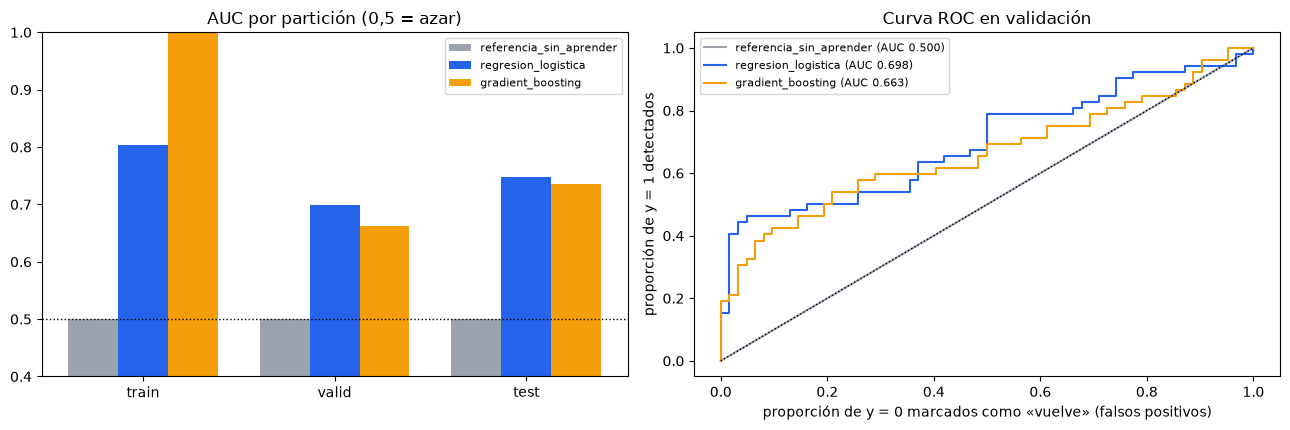

In [9]:
import matplotlib
matplotlib.use('Agg') if os.environ.get('CURSO_SIN_PANTALLA') else None
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

COLOR_MODELO = {'referencia_sin_aprender': '#9ca3af', 'regresion_logistica': '#2563eb', 'gradient_boosting': '#f59e0b'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ancho = 0.26
for i, (nombre, m) in enumerate(resultados.items()):
    ax[0].bar([j + i * ancho for j in range(3)], [m[p]['auc'] for p in ('train', 'valid', 'test')], ancho, label=nombre, color=COLOR_MODELO[nombre])
ax[0].set_xticks([j + ancho for j in range(3)], ['train', 'valid', 'test'])
ax[0].axhline(0.5, color='k', ls=':', lw=1)
ax[0].set_ylim(0.4, 1)
ax[0].set_title('AUC por partición (0,5 = azar)')
ax[0].legend(fontsize=8)
for nombre, m in ajustados.items():
    fpr, tpr, _ = roc_curve(y['valid'], m.predict_proba(X['valid'])[:, 1])
    ax[1].plot(fpr, tpr, label=f"{nombre} (AUC {resultados[nombre]['valid']['auc']:.3f})", color=COLOR_MODELO[nombre])
ax[1].plot([0, 1], [0, 1], 'k:', lw=1)
ax[1].set_xlabel('proporción de y = 0 marcados como «vuelve» (falsos positivos)')
ax[1].set_ylabel('proporción de y = 1 detectados')
ax[1].set_title('Curva ROC en validación')
ax[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(REPORTES / 'figures' / 'comparacion_modelos.png', dpi=110)
plt.show()

## 5. Elegir el mejor con la validación, registrarlo y guardar los artefactos
Se elige el modelo con **mayor AUC en valid** (la referencia queda fuera: solo sirve de mínimo). Después se guarda dos veces, con fines distintos:

| Dónde | Qué | Para qué |
|---|---|---|
| MLflow, ejecución `MEJOR-…` | El modelo con su firma y un ejemplo de entrada | Historial: saber qué modelo era el mejor en cada momento y recuperarlo |
| MLflow, **registro de modelos** | `retencion-90d`, **versión** 1, 2, 3… (una por entrenamiento), enlazada a su ejecución | Dar nombre y versión al modelo elegido; en S4 y S5 se le pone el alias de producción |
| `models/modelo.joblib` | El modelo completo (preprocesamiento + clasificador), serializado | Lo que carga `ia_mlops/modeling/predict.py` |
| `models/modelo_mlflow/` | El mismo modelo en **formato MLflow, con su firma** (nombre y tipo de cada variable) | Lo que carga la API de S2 y se copia a la imagen Docker |
| `models/metadatos.json` | Variables, cortes, filas, huella de los datos, métricas de validación, rangos de train, versiones de librerías | Saber **exactamente** con qué se entrenó y poder reproducirlo |
| `reports/metricas.json` | Las métricas de todos los modelos | Comparar sin abrir MLflow |

*Serializar* es convertir un objeto de Python (el modelo entrenado) en un archivo que se puede guardar y volver a cargar más tarde.

In [10]:
mejor = max((n for n in resultados if n != 'referencia_sin_aprender'), key=lambda n: resultados[n]['valid']['auc'])
modelo = ajustados[mejor]
print('Mejor modelo según la validación:', mejor)

if mlflow:
    with mlflow.start_run(run_name=f'MEJOR-{mejor}'):
        mlflow.log_param('modelo', mejor)
        mlflow.log_param('huella_datos', huella_datos(df))
        for p, m in resultados[mejor].items():
            for k, v in m.items():
                mlflow.log_metric(f'{p}_{k}', v)
        firma = mlflow.models.infer_signature(X['train'].head(200), modelo.predict_proba(X['train'].head(200))[:, 1])
        # cloudpickle evita la verificación de tipos de skops que MLflow 3 aplica a los árboles de scikit-learn.
        # registered_model_name: además de guardarlo en la ejecución, crea una VERSIÓN nueva del modelo «retencion-90d» en el registro.
        info_modelo = mlflow.sklearn.log_model(modelo, name='modelo', signature=firma, serialization_format='cloudpickle', input_example=X['train'].head(3),
                                               registered_model_name='retencion-90d')
    version = info_modelo.registered_model_version
    cliente = mlflow.MlflowClient()
    for clave, valor in (('modelo', mejor), ('huella_datos', huella_datos(df)), ('valid_auc', f"{resultados[mejor]['valid']['auc']:.4f}")):
        cliente.set_model_version_tag('retencion-90d', str(version), clave, valor)   # se ven en la ficha de la versión
    print(f'Registrado en MLflow como «retencion-90d», versión {version}')

joblib.dump(modelo, MODELOS / 'modelo.joblib')

# S2: el mismo modelo en formato MLflow, con su FIRMA (nombre y tipo de cada variable). Es lo que cargará la API y lo que se copia a la imagen Docker.
# Se importa con «from» para no tocar la variable `mlflow` de más arriba (None si USAR_MLFLOW es False).
import shutil
from mlflow.models import infer_signature
from mlflow.sklearn import save_model as guardar_modelo_mlflow
destino_mlflow = MODELOS / 'modelo_mlflow'
if destino_mlflow.exists():
    shutil.rmtree(destino_mlflow)
muestra = X['train'].head(200)
# cloudpickle evita la verificación de tipos de skops que MLflow 3 aplica a los árboles de scikit-learn.
guardar_modelo_mlflow(modelo, str(destino_mlflow), signature=infer_signature(muestra, modelo.predict_proba(muestra)[:, 1]),
                      serialization_format='cloudpickle', input_example=muestra.head(3))
metadatos = {
    'modelo': mejor,
    'objetivo': 'el cliente compra al menos una vez en los siguientes %d dias' % VENTANA_OBJETIVO_DIAS,
    'variables': FEATURES,
    'cortes': CORTES,
    'filas': {k: int(len(v)) for k, v in partes.items()},
    'huella_datos': huella_datos(df),
    'metricas_valid': resultados[mejor]['valid'],
    'rangos_entrenamiento': {c: [float(X['train'][c].min()), float(X['train'][c].max())] for c in X['train'].columns},
    'entrenado_en': datetime.now().isoformat(timespec='seconds'),
    'versiones': {'python': sys.version.split()[0], 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__,
                  'numpy': np.__version__, 'plataforma': platform.system()},
}
(MODELOS / 'metadatos.json').write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding='utf-8')
(REPORTES / 'metricas.json').write_text(json.dumps({'mejor': mejor, 'modelos': resultados}, indent=2), encoding='utf-8')
metadatos

Mejor modelo según la validación: regresion_logistica


C:\bk\bankinter-cowork\utils\miniconda3\envs\env-ia-mlops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/11 11:06:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which 

{'modelo': 'regresion_logistica',
 'objetivo': 'el cliente compra al menos una vez en los siguientes 90 dias',
 'variables': ['recencia_dias',
  'frecuencia',
  'monto_total',
  'ticket_medio',
  'unidades_total',
  'productos_distintos',
  'antiguedad_dias',
  'frecuencia_90d',
  'monto_90d',
  'frecuencia_180d',
  'dias_medios_entre_compras',
  'devoluciones',
  'es_reino_unido'],
 'cortes': {'train': ['2010-06-01',
   '2010-07-01',
   '2010-08-01',
   '2010-09-01',
   '2010-10-01',
   '2010-11-01',
   '2010-12-01'],
  'valid': ['2011-03-01'],
  'test': ['2011-06-01', '2011-09-01']},
 'filas': {'train': 626, 'valid': 114, 'test': 250},
 'huella_datos': '35a94deb4e04ab4a',
 'entrenado_en': '2026-11-11T11:06:35',
 'versiones': {'python': '3.11.18',
  'scikit-learn': '1.9.1',
  'pandas': '2.3.3',
  'numpy': '2.4.6',
  'plataforma': 'Windows'}}

### El elegido, visto como lo vería el negocio (test)
**Izquierda · aciertos por decil.** Se ordenan los clientes de test de mayor a menor probabilidad y se parten en 10 grupos iguales (*deciles*).
Cada barra es la proporción de clientes de ese grupo que **sí** volvieron a comprar; la línea roja es la tasa base. Un buen modelo tiene las barras altas a la
izquierda y bajas a la derecha: si la campaña solo puede llamar al 10 % de los clientes, el decil 1 dice cuántos aciertos tendría.

**Derecha · probabilidades por clase real.** Dos histogramas: las probabilidades que el modelo dio a los que **no** volvieron (gris) y a los que **sí** (azul).
Cuanto menos se solapan, mejor separa el modelo. Nunca se separan del todo: hay clientes que nadie podría adivinar.

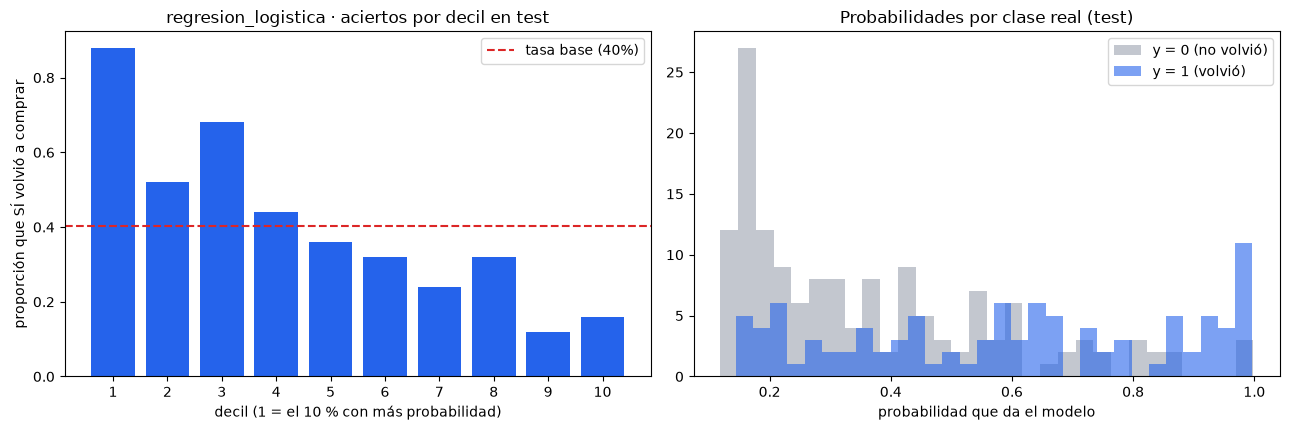

decil
1     0.88
2     0.52
3     0.68
4     0.44
5     0.36
6     0.32
7     0.24
8     0.32
9     0.12
10    0.16
Name: proporción que volvió, dtype: float64

In [11]:
import matplotlib
matplotlib.use('Agg') if os.environ.get('CURSO_SIN_PANTALLA') else None
import matplotlib.pyplot as plt

prob_test = modelo.predict_proba(X['test'])[:, 1]
orden = pd.DataFrame({'prob': prob_test, 'y': y['test'].to_numpy()}).sort_values('prob', ascending=False).reset_index(drop=True)
orden['decil'] = orden.index * 10 // len(orden) + 1
por_decil = orden.groupby('decil')['y'].mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].bar(por_decil.index, por_decil.to_numpy(), color='#2563eb')
ax[0].axhline(y['test'].mean(), color='#dc2626', ls='--', label=f"tasa base ({y['test'].mean():.0%})")
ax[0].set_xticks(range(1, 11))
ax[0].set_xlabel('decil (1 = el 10 % con más probabilidad)')
ax[0].set_ylabel('proporción que SÍ volvió a comprar')
ax[0].set_title(f'{mejor} · aciertos por decil en test')
ax[0].legend()
ax[1].hist(prob_test[y['test'].to_numpy() == 0], bins=30, alpha=0.6, color='#9ca3af', label='y = 0 (no volvió)')
ax[1].hist(prob_test[y['test'].to_numpy() == 1], bins=30, alpha=0.6, color='#2563eb', label='y = 1 (volvió)')
ax[1].set_xlabel('probabilidad que da el modelo')
ax[1].set_title('Probabilidades por clase real (test)')
ax[1].legend()
plt.tight_layout()
fig.savefig(REPORTES / 'figures' / 'mejor_modelo_test.png', dpi=110)
plt.show()
por_decil.round(3).rename('proporción que volvió')

### Recuperar el modelo desde MLflow
Un artefacto sirve si se puede **recuperar**. `log_model` devolvió una referencia al modelo guardado (`info_modelo.model_uri`, con la forma `models:/m-…`).
Con ella se vuelve a cargar y se comprueba que predice **exactamente igual** que el que acabamos de entrenar. También se listan los archivos que MLflow guardó:
- **`MLmodel`**: la ficha del modelo (con qué librería se carga, su firma: qué columnas espera y qué devuelve).
- **`model.pkl`**: el modelo serializado (preprocesamiento + clasificador).
- **`conda.yaml`**, **`python_env.yaml`**, **`requirements.txt`**: las librerías necesarias para volver a cargarlo en otra máquina.
- **`input_example.json`**, **`serving_input_example.json`**: ejemplos de entrada (los usará la API en S2).

In [12]:
if mlflow:
    import mlflow.artifacts
    print('Referencia del modelo en MLflow:', info_modelo.model_uri)
    recuperado = mlflow.sklearn.load_model(info_modelo.model_uri)
    iguales = np.allclose(recuperado.predict_proba(X['test'])[:, 1], modelo.predict_proba(X['test'])[:, 1])
    print('¿El modelo recuperado de MLflow predice igual que el entrenado?', iguales)
    assert iguales
    carpeta_modelo = Path(mlflow.artifacts.download_artifacts(info_modelo.model_uri))
    print('Archivos guardados por MLflow:', sorted(p.name for p in carpeta_modelo.iterdir()))
    print('--- MLmodel (primeras líneas) ---')
    print('\n'.join((carpeta_modelo / 'MLmodel').read_text(encoding='utf-8').splitlines()[:14]))

Referencia del modelo en MLflow: models:/m-02298152961c4cf9a8765a324310b8c5
¿El modelo recuperado de MLflow predice igual que el entrenado? True
Archivos guardados por MLflow: ['MLmodel', 'conda.yaml', 'input_example.json', 'model.pkl', 'python_env.yaml', 'requirements.txt', 'serving_input_example.json']
--- MLmodel (primeras líneas) ---
artifact_path: file:///C:/bk/HC-Cursos/curso-ml-ia-desarrollo-produccion/04-Proyecto-Base/models/mlartifacts/models/m-02298152961c4cf9a8765a324310b8c5/artifacts
flavors:
  python_function:
    env:
      conda: conda.yaml
      virtualenv: python_env.yaml
    loader_module: mlflow.sklearn
    model_path: model.pkl
    predict_fn: predict
    python_version: 3.11.18
  sklearn:
    code: null
    pickled_model: model.pkl
    serialization_format: cloudpickle


## 6. ¿Qué variables importan?
**Importancia por permutación:** se desordena al azar **una** variable en los datos de validación y se mide cuánto cae el AUC.
Si al desordenarla el modelo empeora mucho, el modelo dependía de ella; si no cambia nada, no la usaba. Se repite 5 veces para promediar el azar.
Es una medida **del modelo**, no de la realidad: dice en qué se fija el modelo, no qué causa que un cliente vuelva.

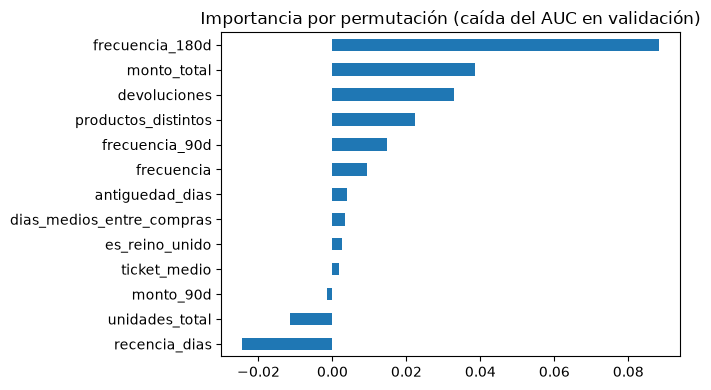

frecuencia_180d              0.0883
monto_total                  0.0386
devoluciones                 0.0329
productos_distintos          0.0222
frecuencia_90d               0.0147
frecuencia                   0.0093
antiguedad_dias              0.0040
dias_medios_entre_compras    0.0033
es_reino_unido               0.0026
ticket_medio                 0.0017
monto_90d                   -0.0016
unidades_total              -0.0115
recencia_dias               -0.0244
dtype: float64

In [13]:
import matplotlib
matplotlib.use('Agg') if os.environ.get('CURSO_SIN_PANTALLA') else None
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

imp = permutation_importance(modelo, X['valid'], y['valid'], scoring='roc_auc', n_repeats=5, random_state=0)
importancia = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
importancia.plot.barh(ax=ax, title='Importancia por permutación (caída del AUC en validación)')
plt.tight_layout()
fig.savefig(REPORTES / 'figures' / 'importancia_variables.png', dpi=110)
plt.show()
importancia.sort_values(ascending=False).round(4)

In [14]:
runs = mlflow.search_runs(experiment_names=['retencion-90d']) if mlflow else None
con.close()
runs[['tags.mlflow.runName', 'metrics.valid_auc', 'metrics.test_auc', 'params.huella_datos']].round(3) if mlflow else None

,tags.mlflow.runName,metrics.valid_auc,metrics.test_auc,params.huella_datos
0,MEJOR-regresion_logistica,0.698,0.747,35a94deb4e04ab4a
1,gradient_boosting,0.663,0.735,35a94deb4e04ab4a
2,regresion_logistica,0.698,0.747,35a94deb4e04ab4a
3,referencia_sin_aprender,0.500,0.500,35a94deb4e04ab4a
4,MEJOR-regresion_logistica,0.698,0.747,35a94deb4e04ab4a
5,gradient_boosting,0.663,0.735,35a94deb4e04ab4a
6,regresion_logistica,0.698,0.747,35a94deb4e04ab4a
7,referencia_sin_aprender,0.500,0.500,35a94deb4e04ab4a
8,MEJOR-regresion_logistica,0.698,0.747,35a94deb4e04ab4a
9,gradient_boosting,0.663,0.735,35a94deb4e04ab4a


### Ver MLflow en el navegador, paso a paso
MLflow trae una interfaz web para explorar el registro. En una terminal **con el entorno activado** y **desde la carpeta `04-Proyecto-Base`**:
```
python -m ia_mlops.mlflow_ui
```
y abre http://127.0.0.1:5000. Si el puerto 5000 está ocupado: `python -m ia_mlops.mlflow_ui --port 5001` y abre http://127.0.0.1:5001.
Por dentro ejecuta `mlflow ui --backend-store-uri sqlite:///…/04-Proyecto-Base/models/mlflow.db` con la **ruta completa** del registro en el que escribió este
cuaderno. Antes de abrir nada, dice cuántas ejecuciones y versiones hay. La terminal se queda ocupada mientras la interfaz está abierta (es normal); se cierra con **Ctrl+C**.

> **Por qué no `mlflow ui --backend-store-uri sqlite:///models/mlflow.db` a secas.** Esa ruta es *relativa*: si la terminal está en otra carpeta (la de VS Code
> se abre en la raíz del repositorio), MLflow **crea allí una base nueva y vacía** sin avisar. La interfaz arranca, pero no hay nada.

0. **Arriba a la izquierda, elige «Model training»** (no «GenAI»). MLflow 3 abre a veces en el modo para IA generativa, con menús de *Traces*, *Prompts*…

1. **Experimentos.** A la izquierda, la lista de experimentos: entra en `retencion-90d`.
2. **Tabla de ejecuciones.** Una fila por ejecución, con su nombre, fecha y duración. Con *Columns* añade `valid_auc`, `test_auc` y `huella_datos` para verlas sin entrar en cada una.
3. **Comparar.** Marca dos o más ejecuciones y pulsa **Compare**: aparecen sus parámetros y métricas lado a lado, y gráficos para ver qué parámetro se asocia a mejor métrica.
4. **Detalle de una ejecución.** Haz clic en el nombre: *Parameters*, *Metrics* y, en la ejecución `MEJOR-…`, el modelo registrado con su firma y sus archivos.
5. **Modelos.** En MLflow 3 los modelos guardados con `log_model` también aparecen en la pestaña de modelos del experimento (*Models*), cada uno con su id `m-…`.
6. **Registro de modelos.** En el menú izquierdo, **Model registry**: el modelo `retencion-90d` con su última versión. Entra en una versión: verás de qué
   ejecución salió (*Source Run*: `MEJOR-…`), sus etiquetas (`modelo`, `huella_datos`, `valid_auc`) y su firma (13 entradas, 1 salida).
   Cada vez que vuelves a entrenar aparece una versión nueva: las anteriores no se borran.

**Si no ves nada:** lanza `python -m ia_mlops.mlflow_ui --comprobar`: dice qué registro lee y cuántas ejecuciones y versiones tiene. Si da 0, ejecuta este
cuaderno con `USAR_MLFLOW = True`. Si ves menús de *Traces* o *Prompts*, cambia a **Model training**.
**Para empezar de cero:** cierra la interfaz y borra `models/mlflow.db` y `models/mlartifacts/`; el próximo entrenamiento los vuelve a crear. No se editan a mano.

**Qué viene después.** En S4 y S5, sobre este mismo registro: poner a una versión el **alias** de producción, cargar el modelo por su alias
(`models:/retencion-90d@produccion`) y volver a la versión anterior si la nueva falla (*rollback*).

## Resumen
- Tres modelos entrenados con train y comparados con valid; el mejor, evaluado una sola vez con test.
- Cada entrenamiento es una **ejecución** del **experimento** `retencion-90d` en MLflow, con sus parámetros, métricas y, para el mejor, el modelo.
- Todo se guarda en `models/mlflow.db` (textos y números) y `models/mlartifacts/` (archivos), se puede consultar desde Python (`search_runs`) o desde la web (`mlflow ui`),
  y el modelo se puede **recuperar** desde MLflow y predice igual.
- El modelo elegido queda también en `models/modelo.joblib` con sus metadatos: es lo que usará la API en S2.

## Para practicar (tarea de S1)
1. Abre la interfaz (`python -m ia_mlops.mlflow_ui`), entra en `retencion-90d` y compara `regresion_logistica` con `gradient_boosting`. ¿Cuál tiene más diferencia entre `train_auc` y `valid_auc`? ¿Qué significa?
2. Vuelve a ejecutar este cuaderno sin cambiar nada. ¿Cuántas ejecuciones tiene ahora el experimento? ¿Y cuántas versiones el modelo registrado? ¿Coinciden las métricas y la `huella_datos`?
3. Con la variable nueva que añadiste a FS: reconstruye ML, vuelve a entrenar y **compara en MLflow** dos ejecuciones (antes y después). ¿Mejoró el AUC de validación? ¿Cambió la huella? Explica tu decisión.